# Question 2 - Section 338 tariff exposure and legal completeness
**Reproducible analysis notebook | Legal reference date: October 12, 2026**

**Flow:** Original proclamations → annex HTS codes → amendments / suspensions / exclusions → 2026 HTS revision → HS6 harmonization → 2025 provincial domestic exports to U.S. → exposed HS6/HS4 → province comparisons → decision-maker briefing.

**Note:** This notebook calculates *partial HS6 product-category screening only*. It deliberately does **not** calculate or label a definitive Canada-wide Section 338 exposure. Import prohibitions are separate from tariff measures.

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
P = ROOT / 'data' / 'processed'
OUT = ROOT / 'deliverables' / 'notebook_outputs'
OUT.mkdir(parents=True, exist_ok=True)
print('Project:', ROOT)

Project: /mnt/data/alberta_trade_Q1_Q2_notebook_deliverables


## A. Source completeness and legal verification gate

In [ ]:
import json
for fn in ['status.json','legal_reconciliation_status.json','combined_partial_status.json']:
 p=P/'q2'/fn
 print('\n',fn, '\n',p.read_text()[:2200] if p.exists() else 'NOT FOUND')
legal_verified=False
print('CERTIFIED FULL TARIFF UNIVERSE:',legal_verified)
assert not legal_verified, 'Remove this guard only after a documented code-level legal audit.'


 status.json 
 {
  "export_source": "Original supplied Statistics Canada CIMT 2025 domestic exports ODPFN018 HS6",
  "year": 2025,
  "province_count": 13,
  "total_canada_us_domestic_exports_cad": 517282733046.0,
  "legal_measure_rows_verified": 0,
  "policy_as_of": "2026-10-12",
  "tariff_exposure_status": "BLOCKED_UNTIL_VERIFIED_HTS_LIST",
  "prohibition_exposure_status": "BLOCKED_UNTIL_VERIFIED_HTS_LIST",
  "warning": "Do not equate HS6 exposure with exact HTS8/HTS10 coverage; partial matches are upper-bound category values."
}

 legal_reconciliation_status.json 
 {
  "as_of": "2026-10-12",
  "active_tariff_universe_complete": false,
  "certified_exposure_permitted": false,
  "original_proclamation_annexes_extracted_completely": false,
  "known_amendment_additions_active": 82,
  "unique_amendment_hs6": 48,
  "unmatched_removals_to_reconcile_against_originals": 8,
  "prohibition_events_separate": 1,
  "note": "Partial HS6 category screening only; do not interpret as duties paid, tra

## B. Provincial denominators (all 13 jurisdictions)

In [ ]:
den=pd.read_csv(P/'q2/provincial_us_exports_2025_denominators.csv')
assert len(den)==13 and den['province_code'].nunique()==13
display(den.sort_values('value_cad',ascending=False))
print('Canada 2025 domestic exports to U.S. CAD:',f"{den['value_cad'].sum():,.0f}")

,province_code,province_name,value_cad
0,ON,Ontario,190317873807
1,AB,Alberta,152042164486
2,QC,Quebec,84339012465
3,BC,British Columbia,27916212374
4,SK,Saskatchewan,23683450602
5,NB,New Brunswick,14473068963
6,MB,Manitoba,12942004807
7,NL,Newfoundland and Labrador,4760459611
8,NS,Nova Scotia,4584131237
9,PE,Prince Edward Island,2035426507


Canada 2025 domestic exports to U.S. CAD: 517,282,733,046


## C. Partial screening: NOT total Section 338 tariff exposure

In [ ]:
s=pd.read_csv(P/'q2/combined_partial_provinces_NOT_TOTAL_EXPOSURE.csv')
assert len(s)==13
assert np.allclose(s['screened_pct'],100*s['screened_hs6_cad']/s['total_exports_cad'],atol=1e-5)
s=s.sort_values('screened_hs6_cad',ascending=False)
display(s)
s.to_csv(OUT/'q2_PARTIAL_provincial_screen_NOT_TOTAL_EXPOSURE.csv',index=False)
print('Partial HS6 category screening CAD:',f"{s['screened_hs6_cad'].sum():,.0f}")

,province_code,province_name,total_exports_cad,screened_hs6_cad,screened_pct
0,ON,Ontario,190317873807,3.483621e+09,1.830422
1,QC,Quebec,84339012465,2.013972e+09,2.387949
2,BC,British Columbia,27916212374,2.761333e+08,0.989150
3,NS,Nova Scotia,4584131237,2.592034e+08,5.654362
4,NB,New Brunswick,14473068963,2.178426e+08,1.505159
5,AB,Alberta,152042164486,1.812890e+08,0.119236
6,MB,Manitoba,12942004807,1.622773e+08,1.253881
7,SK,Saskatchewan,23683450602,2.451083e+07,0.103494
8,NL,Newfoundland and Labrador,4760459611,3.560190e+05,0.007479
9,PE,Prince Edward Island,2035426507,2.248240e+05,0.011046


Partial HS6 category screening CAD: 6,619,437,433


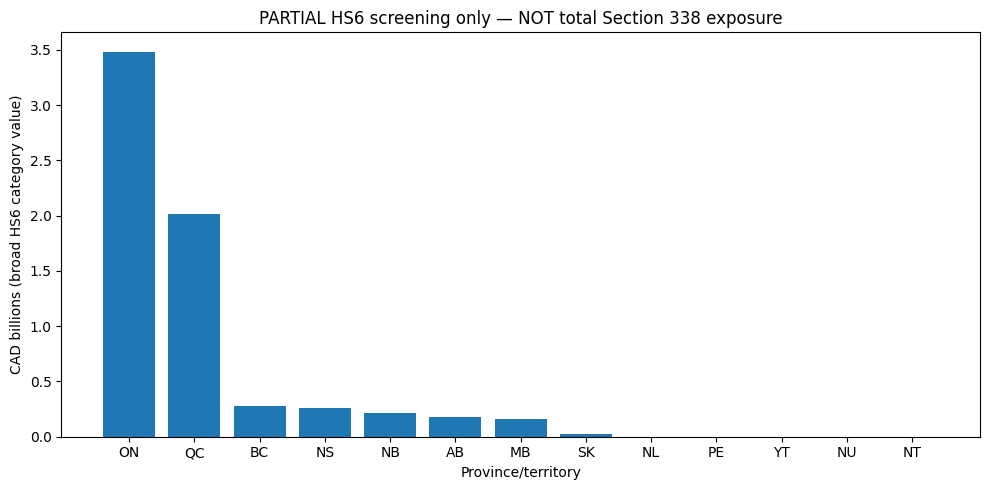

In [ ]:
fig,ax=plt.subplots(figsize=(10,5))
ax.bar(s['province_code'],s['screened_hs6_cad']/1e9)
ax.set(title='PARTIAL HS6 screening only — NOT total Section 338 exposure',ylabel='CAD billions (broad HS6 category value)',xlabel='Province/territory')
plt.tight_layout();fig.savefig(OUT/'q2_PARTIAL_screen_by_province.png',dpi=170);plt.show()

## D. Alberta HS4 product screen

In [ ]:
ab=pd.read_csv(P/'q2/combined_partial_alberta_hs4_NOT_TOTAL_EXPOSURE.csv',dtype={'hs4':str})
ab=ab.sort_values('screened_hs6_cad',ascending=False)
display(ab.head(15))
ab.to_csv(OUT/'q2_PARTIAL_alberta_hs4_NOT_TOTAL_EXPOSURE.csv',index=False)

,hs4,screened_hs6_cad,all_exports_in_hs4_cad,hs4_screened_pct
0,9403,64975466,175997528,36.918397
1,7308,58719868,61580716,95.354312
2,7604,27402822,27402822,100.000000
3,2204,17458323,17458323,100.000000
4,9401,5893244,12509552,47.109952
5,8307,2864986,2864986,100.000000
6,8311,1046011,1061003,98.586997
7,9404,721680,1607945,44.882132
8,7608,664488,664488,100.000000
9,8308,626609,626609,100.000000


## E. Separate import-prohibition register

In [ ]:
prohib=P/'q2/prohibition_events_SEPARATE.csv'
if prohib.exists():
 pr=pd.read_csv(prohib,dtype=str);display(pr.head(10));print('Prohibition rows:',len(pr))
else:print('No prohibition events file found')

,document_id,annex,action,hts_code,measure_type,additional_duty_rate,effective_from,effective_to,legal_url,verified,reviewer_note,hts_digits,hs6,hs4
0,11063,I,prohibit,8711.50.00,prohibition,NaN,2026-09-29,NaN,https://www.govinfo.gov/content/pkg/FR-2026-09...,yes,Directly read FR p. 58329; prohibition not tariff,87115000,871150,8711


Prohibition rows: 1


## F. References

Executive Office of the President. (2026a, July 23). *Imposing additional duties ... with respect to alcoholic beverages* (Proclamation No. 11046). *Federal Register, 91*, 46639–46652. https://www.govinfo.gov/content/pkg/FR-2026-07-23/pdf/2026-14991.pdf

Executive Office of the President. (2026b, July 23). *Imposing additional duties ... with respect to dairy* (Proclamation No. 11047). *Federal Register, 91*, 46653–46661. https://www.govinfo.gov/content/pkg/FR-2026-07-23/pdf/2026-14992.pdf

Executive Office of the President. (2026c, July 23). *Imposing additional duties ... with respect to motor vehicles* (Proclamation No. 11048). *Federal Register, 91*, 46663–46688. https://www.govinfo.gov/content/pkg/FR-2026-07-23/pdf/2026-14997.pdf

United States International Trade Commission. (2026, October 9). *2026 harmonized tariff schedule, revision 21* [Data set]. https://www.usitc.gov/harmonized_tariff_information/hts/archive/list

Statistics Canada. (2026). *Canadian international merchandise trade: Domestic exports, 2025* [Data set]. https://www.statcan.gc.ca/